# 06 · Figures for the report and the presentation
Reads the result tables written by notebooks 02 and 03.

In [1]:
import sys, pathlib
sys.path.insert(0, str(pathlib.Path.cwd().parent / "src"))
import numpy as np, pandas as pd, matplotlib.pyplot as plt
from config import OUT
INK, INK2, MUTED, GRID, BASE, SURF = "#0b0b0b", "#52514e", "#898781", "#e1e0d9", "#c3c2b7", "#fcfcfb"
COL = {"A internal": "#2a78d6", "B A+all external": "#eb6834", "C A+coordinates": "#1baf7a"}
LAB = {"A internal": "A  listing attributes only", "B A+all external": "B  + 5 external sources (no coordinates)", "C A+coordinates": "C  + latitude, longitude, arrondissement"}
PROT = {"host": "Unseen hosts", "spatial": "Unseen 1 km cells", "block": "Unseen 3 km blocks"}
plt.rcParams.update({"font.size": 10, "axes.edgecolor": BASE, "axes.labelcolor": INK2, "xtick.color": INK2, "ytick.color": MUTED,
                     "figure.facecolor": SURF, "axes.facecolor": SURF})

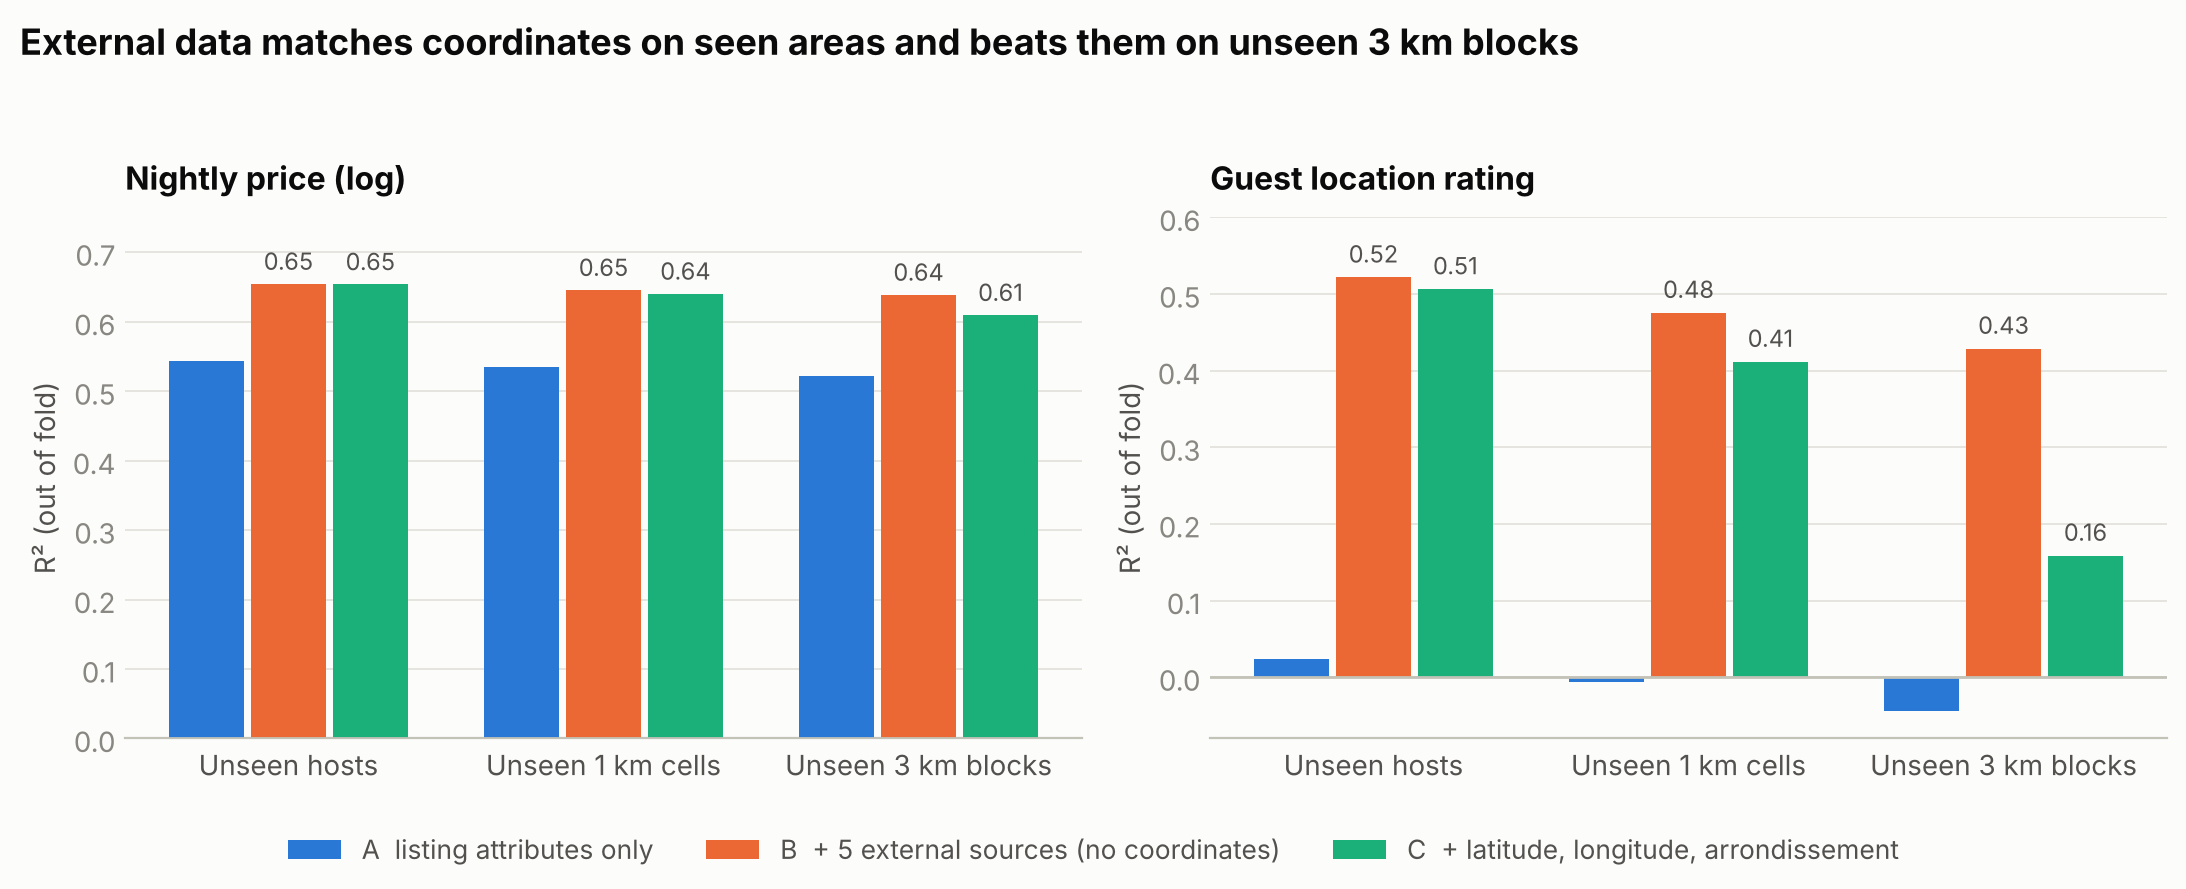

In [2]:
def panel(ax, f, title):
    d = pd.read_csv(f); w = 0.26; x = np.arange(3)
    for i, k in enumerate(COL):
        v = [d[(d.protocol == p) & (d.features == k)].R2.iloc[0] for p in PROT]
        ax.bar(x + (i - 1) * w, v, w - 0.02, color=COL[k], label=LAB[k], zorder=3)
        if k != "A internal":
            for xi, vi in zip(x + (i - 1) * w, v): ax.text(xi, vi + 0.012, f"{vi:.2f}", ha="center", va="bottom", fontsize=8.5, color=INK2)
    ax.set_xticks(x, list(PROT.values())); ax.axhline(0, color=BASE, lw=1, zorder=4)
    ax.yaxis.grid(True, color=GRID, lw=0.6, zorder=0); ax.set_axisbelow(True)
    for s in ("top", "right", "left"): ax.spines[s].set_visible(False)
    ax.tick_params(length=0); ax.set_title(title, loc="left", color=INK, fontsize=11.5, fontweight="bold", pad=10); ax.set_ylabel("R² (out of fold)")

fig, axs = plt.subplots(1, 2, figsize=(11, 4.4))
panel(axs[0], OUT / "t1_price.csv", "Nightly price (log)"); axs[0].set_ylim(0, 0.75)
panel(axs[1], OUT / "t8_rating.csv", "Guest location rating"); axs[1].set_ylim(-0.08, 0.6)
h, l = axs[0].get_legend_handles_labels(); fig.legend(h, l, loc="lower center", ncol=3, frameon=False, fontsize=9.5, labelcolor=INK2)
fig.suptitle("External data matches coordinates on seen areas and beats them on unseen 3 km blocks", x=0.01, ha="left", fontsize=13, color=INK, fontweight="bold")
fig.tight_layout(rect=(0, 0.08, 1, 0.94)); fig.savefig(OUT / "figures" / "r2_by_holdout.png", dpi=180); plt.show()

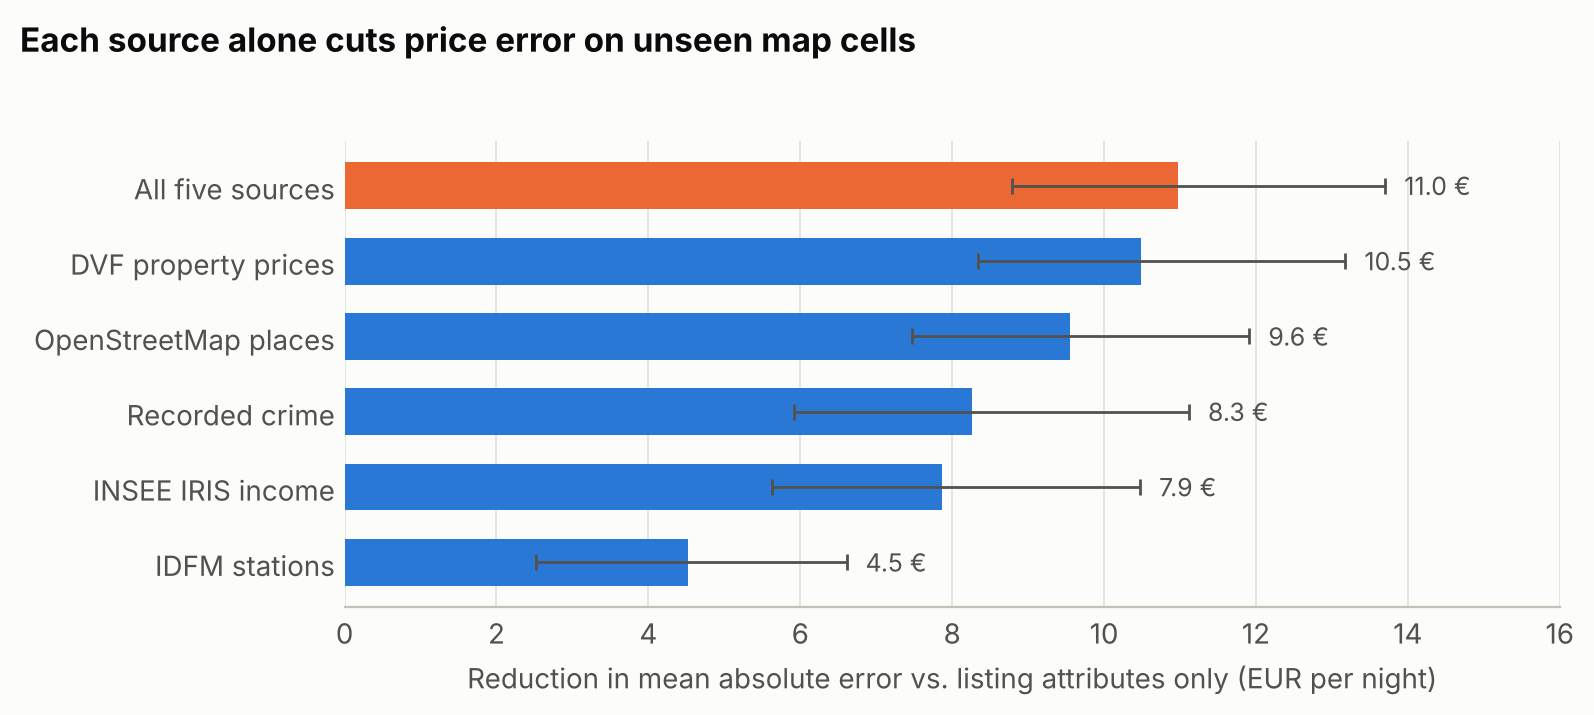

In [3]:
e = pd.read_csv(OUT / "t1_price_mae_eur.csv"); e = e[(e.protocol == "spatial") & (e["from"] == "A internal")].copy()
name = {"A+stations": "IDFM stations", "A+osm": "OpenStreetMap places", "A+dvf": "DVF property prices", "A+iris_income": "INSEE IRIS income",
        "A+crime": "Recorded crime", "B A+all external": "All five sources"}
e["n"] = e["to"].map(name); e = e.sort_values("mae_reduction_eur")
fig, ax = plt.subplots(figsize=(8, 3.6)); y = np.arange(len(e))
ax.barh(y, e.mae_reduction_eur, 0.62, color=["#eb6834" if t == "B A+all external" else "#2a78d6" for t in e["to"]], zorder=3)
ax.errorbar(e.mae_reduction_eur, y, xerr=[e.mae_reduction_eur - e.ci95_low, e.ci95_high - e.mae_reduction_eur], fmt="none", ecolor=INK2, lw=1, capsize=3, zorder=4)
for yi, v, hi in zip(y, e.mae_reduction_eur, e.ci95_high): ax.text(hi + 0.25, yi, f"{v:.1f} €", va="center", fontsize=9, color=INK2)
ax.set_yticks(y, e.n); ax.tick_params(axis="y", colors=INK2); ax.xaxis.grid(True, color=GRID, lw=0.6, zorder=0); ax.set_axisbelow(True)
for s in ("top", "right", "left"): ax.spines[s].set_visible(False)
ax.tick_params(length=0); ax.set_xlim(0, 16); ax.set_xlabel("Reduction in mean absolute error vs. listing attributes only (EUR per night)")
fig.suptitle("Each source alone cuts price error on unseen map cells", x=0.01, ha="left", fontsize=12, fontweight="bold", color=INK)
fig.tight_layout(rect=(0, 0, 1, 0.95)); fig.savefig(OUT / "figures" / "price_gain_by_source.png", dpi=180); plt.show()